# ZMAP Plotting


## Environment Setup



In [ ]:
# Install from pip
!pip -q install zmap-tools
import zmap

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.9/18.9 MB 137.9 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  error: subprocess-exited-with-error
  
  × Preparing metadata (pyproject.toml) did not run successfully.
  │ exit code: 1
  ╰─> See above for output.
  
  note: This error originates from a subprocess, and is likely not a problem with pip.
  Preparing metadata (pyproject.toml) ... error
error: metadata-generation-failed

× Encountered error while generating package metadata.
╰─> See above for output.

note: This is an issue with the package mentioned above, not pip.
hint: See above for details.


ModuleNotFoundError: No module named 'zmap'

Recommended for Colab: Mount a persistent Google Drive. ZMAP will download and cache files at: /content/drive/MyDrive/zmap


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

## Get ZMAP Reference h5ads

The first run of this command will download the ZMAP h5ad reference and load it into memory. If ZMAP is able to cache files locally or on a mounted GDrive, then ***subsequent downloads will not be needed.***

Speficy which version of the ZMAP reference to load using the "kind" parameter:

* **"processed_slim_tpm"** — fully processed, TPM counts only,
recommended for plotting (default)

* **"processed_slim"**     — fully processed, raw counts only

* **"processed"**          — fully processed, includes all intermediate layers (large ~22GB)

* **"raw"**                — raw counts, unprocessed

* **"symphony"**           — Symphony reference, used internally by zmap.predict
Required for annotate_with_zmap. <br><br>

In [ ]:
adata = zmap.ref.load_zmap_h5ad(kind='processed_slim_tpm')

[ZMAP] Using cached file: /content/drive/MyDrive/zmap/h5ad/ZMAP_251209_processed_slim_tpm.h5ad
[ZMAP] Loading into memory from /content/drive/MyDrive/zmap/h5ad/ZMAP_251209_processed_slim_tpm.h5ad


## ZMAP Style DotPlots

In [ ]:
from zmap.dotplot.dotplot_gene import gene_groups_vs_time

In [ ]:
DEFAULT_CLUSTER_ORDER_ZMAP_Tissue = [
    'blastomeres',
    'ectoderm_early', 'epidermis', 'ionocyte_epithelium', 'placodes',
    'endoderm_early', 'pharyngeal', 'intestine', 'liver', 'pancreas',
    'neural_crest',
    'neural_early', 'eye', 'forebrain', 'midbrain', 'hindbrain', 'spinal_cord', 'neurons',
    'mesoderm_early', 'axial_meso', 'somitic_meso', 'muscle', 'lateral_plate', 'endothelial', 'fin_bud', 'heart', 'hematopoietic', 'intermediate_meso',
    'primordial_germ_cell',
    ]


In [ ]:
DEFAULT_ROW_DIVIDERS_ZMAP_Tissues = [1, 5, 12, 13, 18, 28]

In [ ]:
DEFAULT_ROW_COLOR_GROUPS_ZMAP_Tissue = {
    "black":      ["blastomeres"],
    "green":      ['ectoderm_early', 'epidermis', 'ionocyte_epithelium', 'placodes'],
    "darkorange": ['endoderm_early', 'pharyngeal', 'intestine', 'liver', 'pancreas'],
    "steelblue":  ['neural_crest'],
    "blue":       ['neural_early', 'eye', 'forebrain', 'midbrain', 'hindbrain', 'spinal_cord', 'neurons'],
    "darkblue":   ['optic_cup', 'retinal_pigment_epithelium', 'retina', 'photoreceptors'],
    "red":        ['mesoderm_early', 'axial_meso', 'somitic_meso', 'muscle', 'lateral_plate', 'endothelial', 'fin_bud', 'heart', 'hematopoietic', 'intermediate_meso'],
    "purple":     ["primordial_germ_cell"],
}

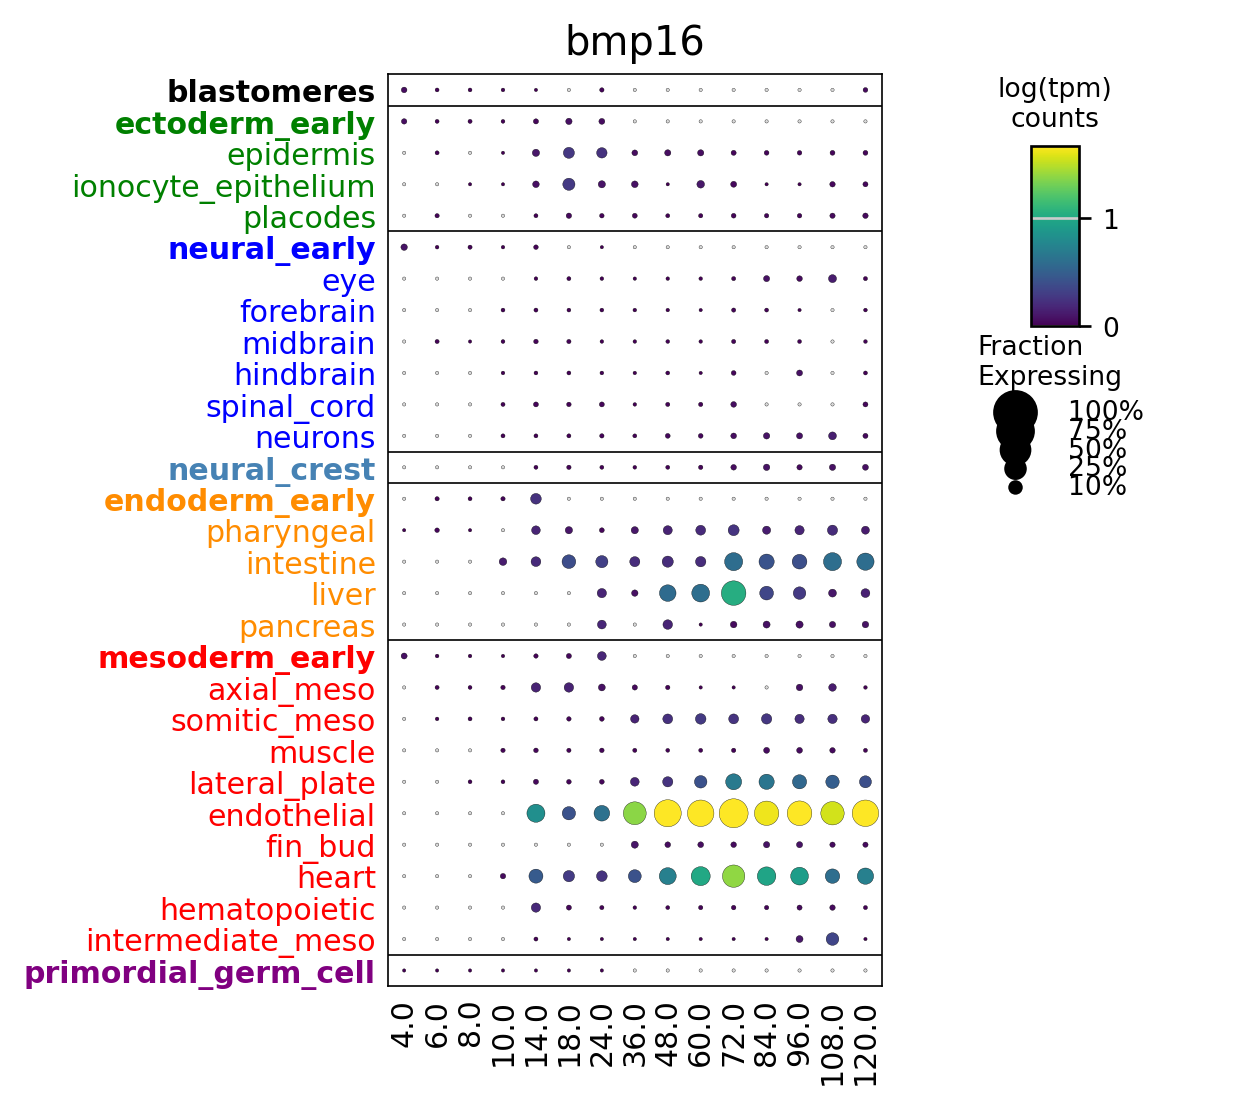

In [ ]:
f = gene_groups_vs_time(
        adata,
        groupby='ZMAP_Tissue',
        color='bmp16',
        base_col_width= 0.2, base_row_height = 0.12,
        s_min=1, s_max=180,
        figsize=(4, 5),
        cluster_order=DEFAULT_CLUSTER_ORDER_ZMAP_Tissue,
        row_color_groups=DEFAULT_ROW_COLOR_GROUPS_ZMAP_Tissue,
        row_dividers=DEFAULT_ROW_DIVIDERS_ZMAP_Tissues)

f[0].figure.savefig('bmp16_ZMAP_Tissue_dotplot.pdf', dpi=600, bbox_inches='tight')

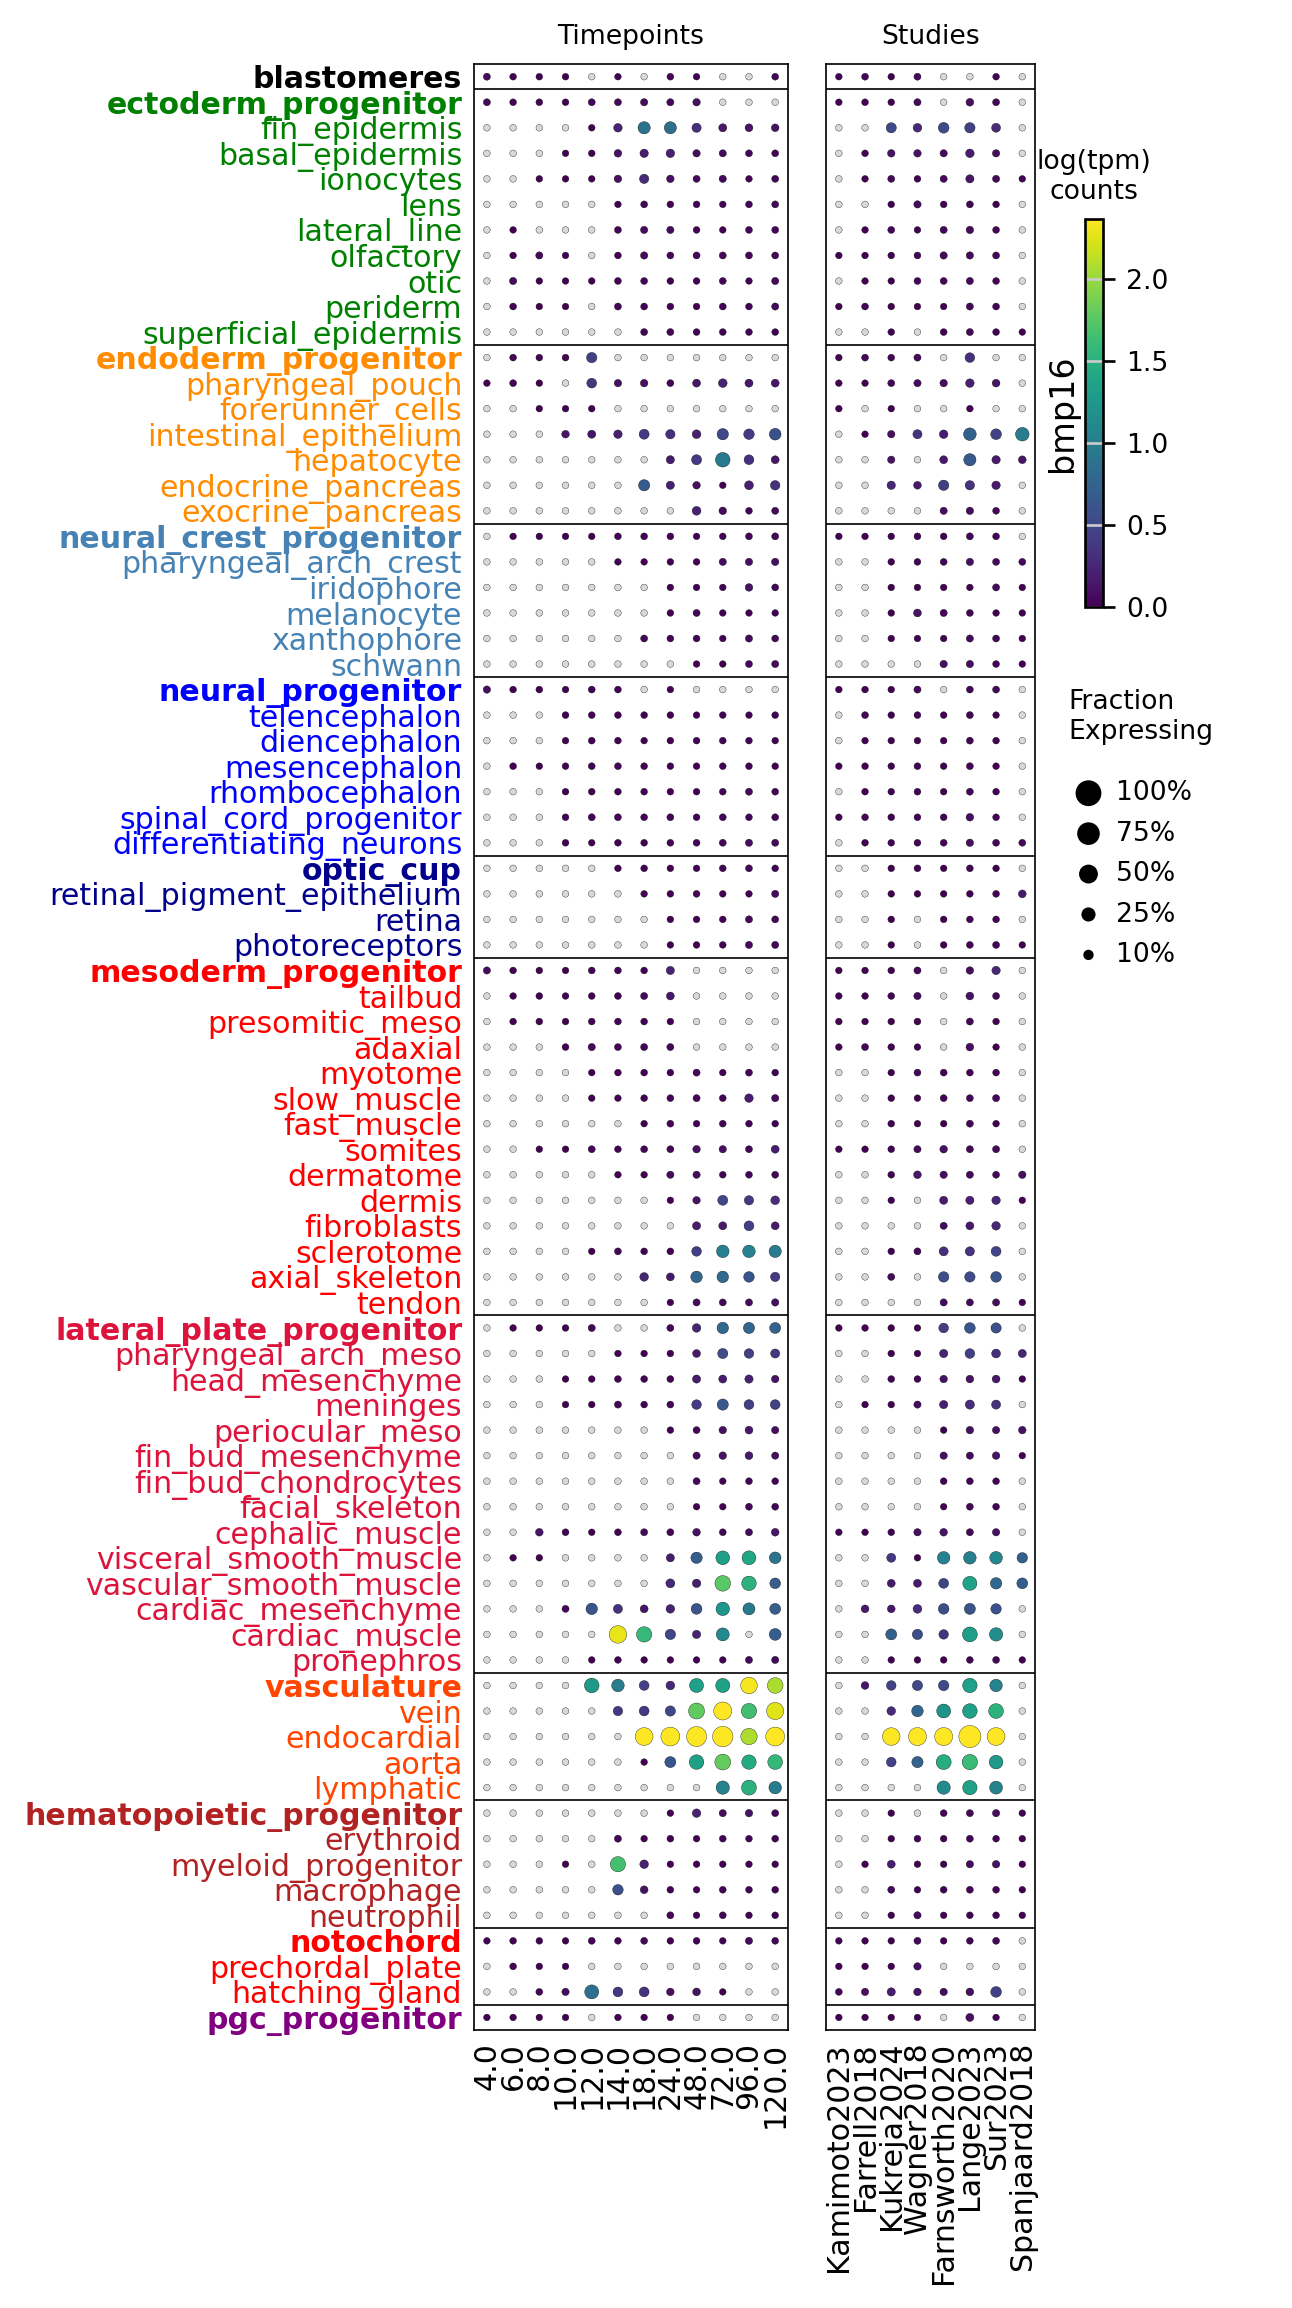

In [ ]:
zmap.dotplot.gene_view(adata, color='bmp16');

## ScanPy Plots

In [ ]:
import scanpy as sc

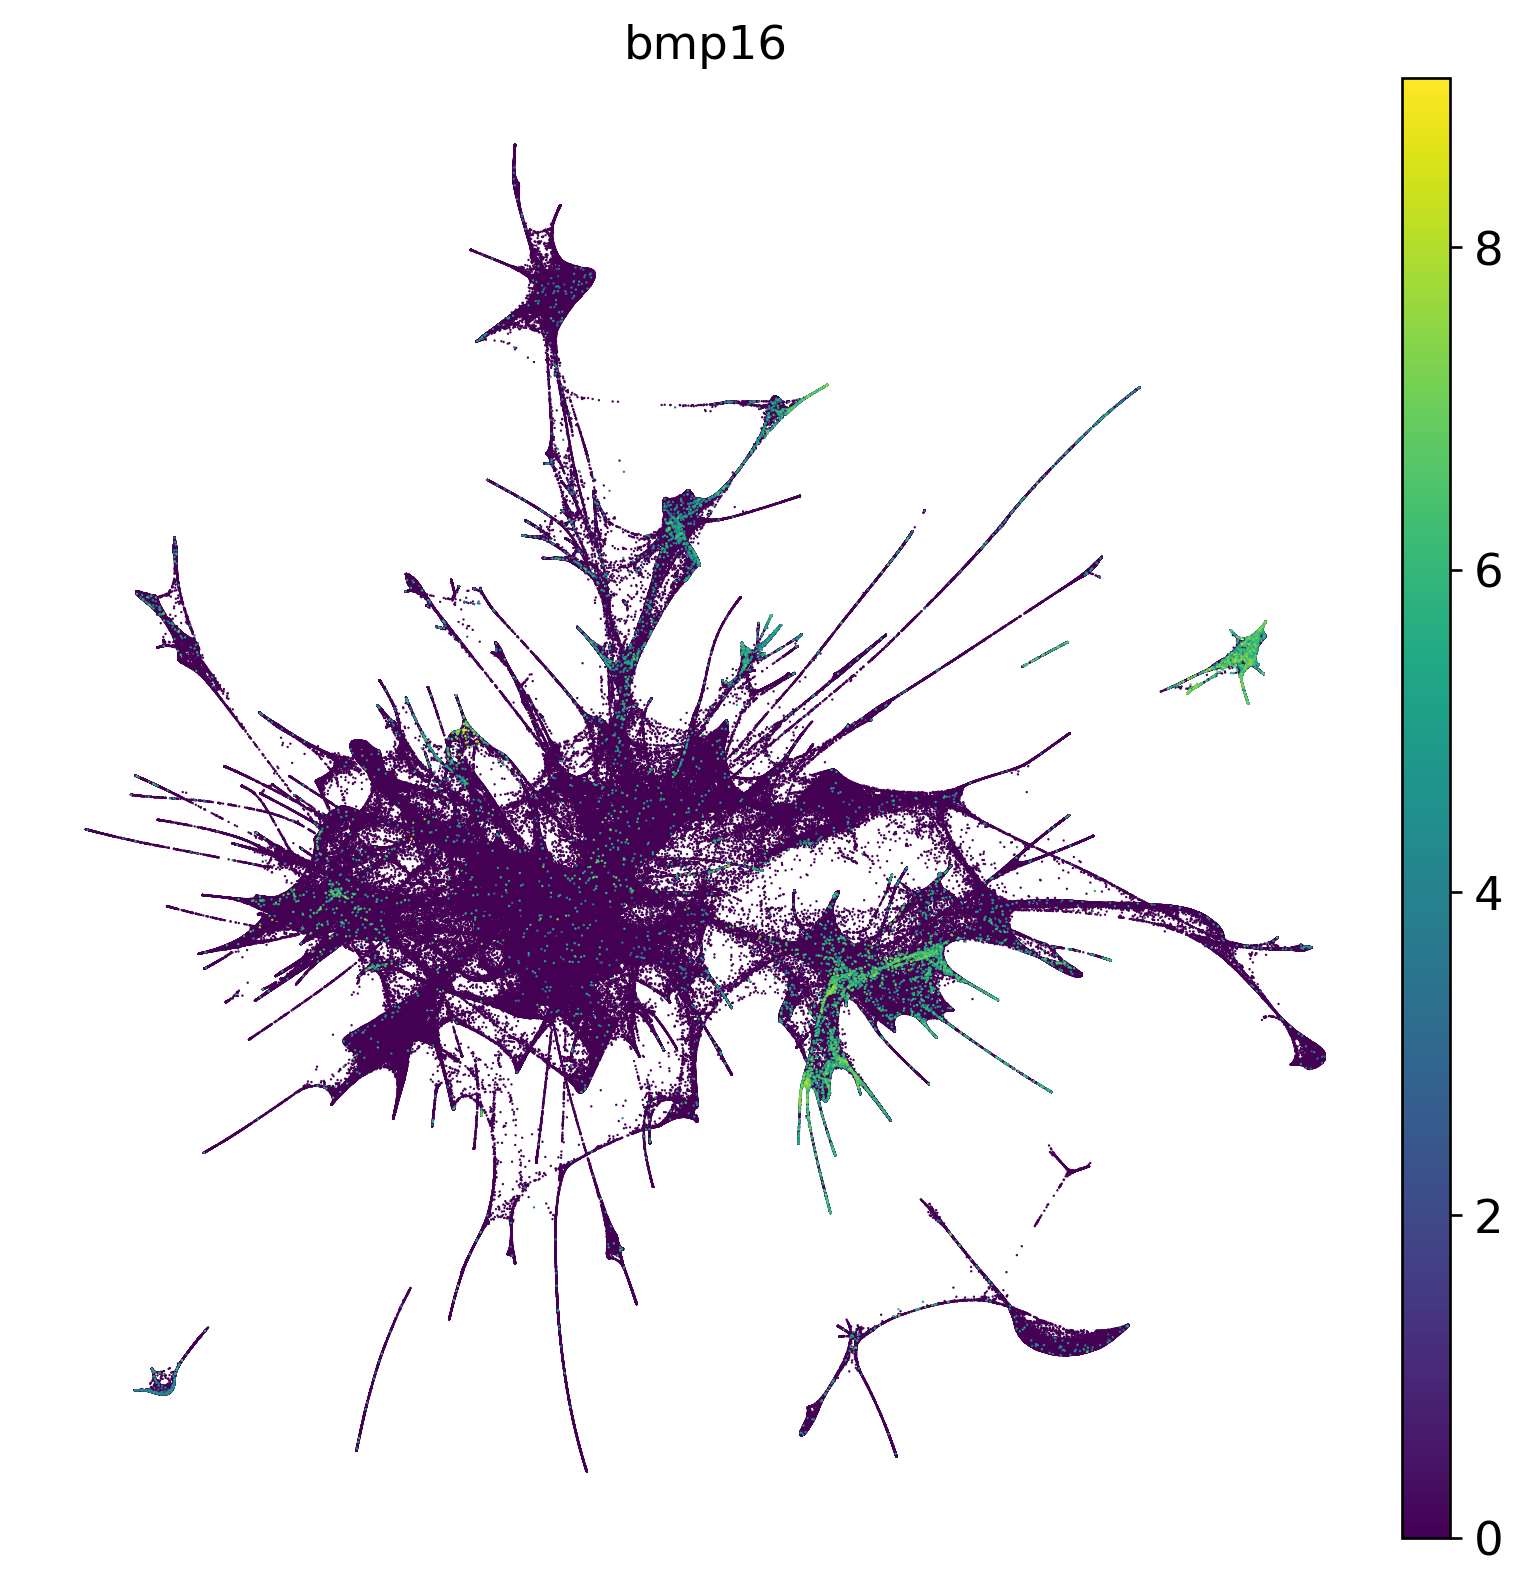

In [ ]:
sc.set_figure_params(figsize=(8, 8), dpi=120)

f = sc.pl.umap(
        adata,
        color='bmp16',
        layer='tpm_log', s=2,
        frameon=False,
        show=True,
        return_fig=True)

f.figure.savefig('bmp16_ZMAP_umap.pdf', dpi=600, bbox_inches='tight')
